# Social Network Analysis: Important Nodes and Communities Using Matrix Methods

**Goal:** analyze a social network to identify important nodes and investigate its communities using matrix-based network measures.

**Linear algebra ideas used**
1. **Adjacency matrix** $A$ - the network written as a matrix.
2. **Eigenvalues and eigenvectors** of $A$ - the leading eigenvector gives *eigenvector centrality* (important nodes).
3. **Spectral ideas** - the Laplacian $L = D - A$ and its Fiedler vector, and the modularity matrix $B$, whose eigenvectors reveal communities.

**Note:** the eigen-decompositions below use dense matrices, which suits networks of up to a few thousand nodes.

In [2]:
import numpy as np
import networkx as nx
import matplotlib.pyplot as plt

In [3]:
raw_network = nx.read_edgelist('tiktok_combined.txt.gz', nodetype=int)

largest_component = max(nx.connected_components(raw_network), key=len)
social_network = raw_network.subgraph(largest_component).copy()
social_network.remove_edges_from(list(nx.selfloop_edges(social_network)))

nodes = sorted(social_network.nodes())        # fixed node order = row/column order of the matrices
n = len(nodes)
m = social_network.number_of_edges()

print(f"Original network : {raw_network.number_of_nodes()} nodes, {raw_network.number_of_edges()} edges")
print(f"Analysed network : {n} nodes, {m} edges (largest connected component)")

Original network : 4039 nodes, 88234 edges
Analysed network : 4039 nodes, 88234 edges (largest connected component)


In [4]:
pos = nx.spring_layout(social_network, seed=25, k=0.06)

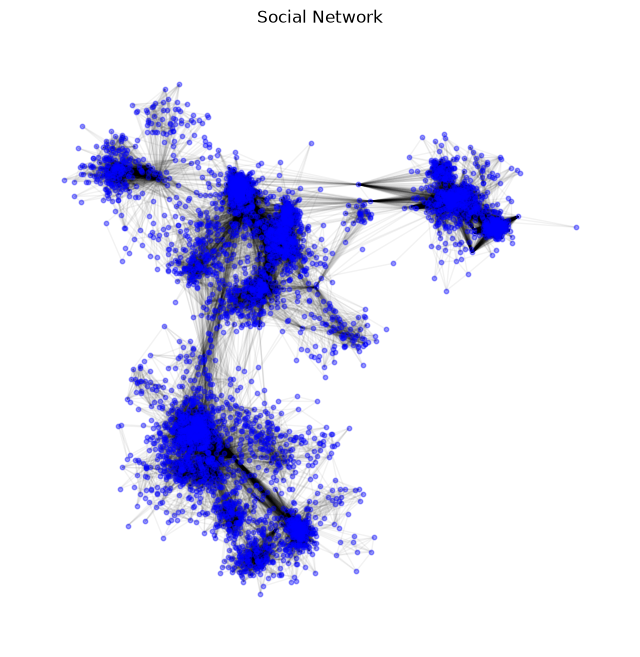

In [5]:
fig, ax = plt.subplots(figsize=(8, 8))
nx.draw_networkx_nodes(social_network, pos, node_size=10, node_color='blue', alpha=0.4, ax=ax)
nx.draw_networkx_edges(social_network, pos, alpha=0.05, ax=ax)
ax.set_title("Social Network")
ax.axis('off')
plt.show()

## 2. Adjacency matrix

$A_{ij} = 1$ if nodes $i$ and $j$ are connected, otherwise $0$. For an undirected network $A$ is symmetric.
The degree of every node is a row sum of $A$, i.e. the vector $\mathbf{d} = A\mathbf{1}$.

In [6]:
A = nx.to_numpy_array(social_network, nodelist=nodes)

print("Shape of A          :", A.shape)
print("A is symmetric      :", np.allclose(A, A.T))
print("Zero diagonal       :", np.all(np.diag(A) == 0))
print("Non-zero entries    :", int(A.sum()), "(= 2 x number of edges =", 2 * m, ")")
print("Density             : %.5f" % (A.sum() / (n * (n - 1))))

Shape of A          : (4039, 4039)
A is symmetric      : True
Zero diagonal       : True
Non-zero entries    : 176468 (= 2 x number of edges = 176468 )
Density             : 0.01082


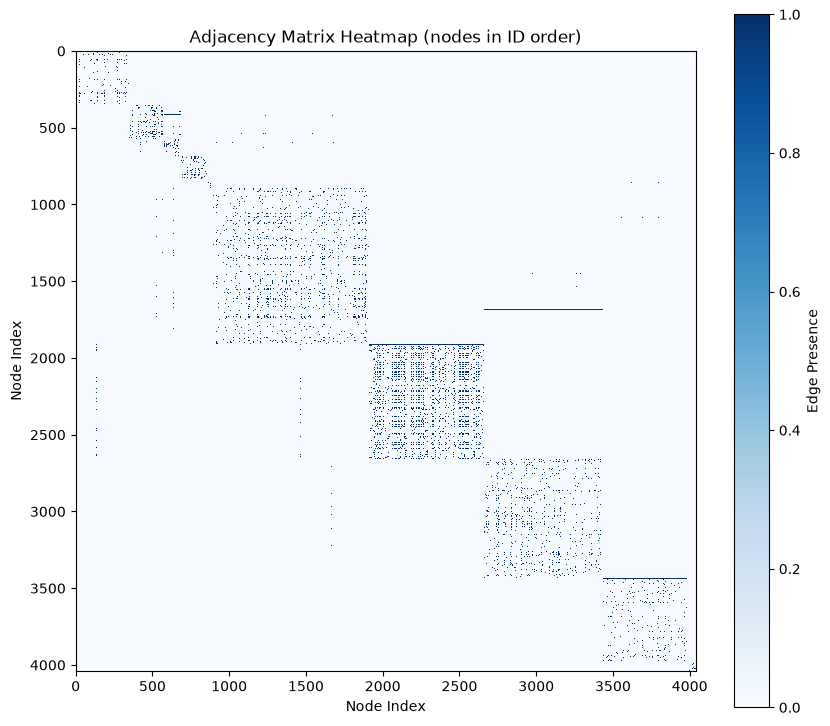

In [7]:
plt.figure(figsize=(10, 9))
plt.imshow(A, cmap='Blues', interpolation='nearest')
plt.colorbar(label='Edge Presence')
plt.title('Adjacency Matrix Heatmap (nodes in ID order)')
plt.xlabel('Node Index')
plt.ylabel('Node Index')
plt.show()

Average degree : 43.69
Maximum degree : 1045


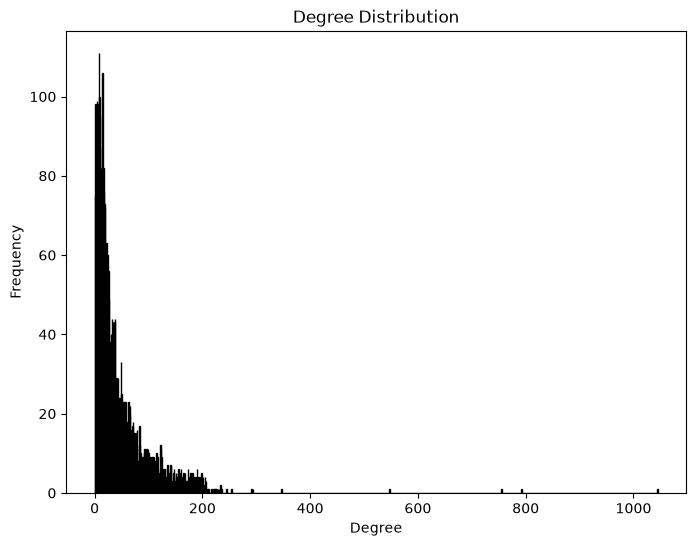

In [8]:
degrees = A.sum(axis=1)                       # d = A . 1
print("Average degree :", round(degrees.mean(), 2))
print("Maximum degree :", int(degrees.max()))

plt.figure(figsize=(8, 6))
plt.hist(degrees, bins=np.arange(0, degrees.max() + 2) - 0.5, edgecolor='black')
plt.xlabel('Degree')
plt.ylabel('Frequency')
plt.title('Degree Distribution')
plt.show()

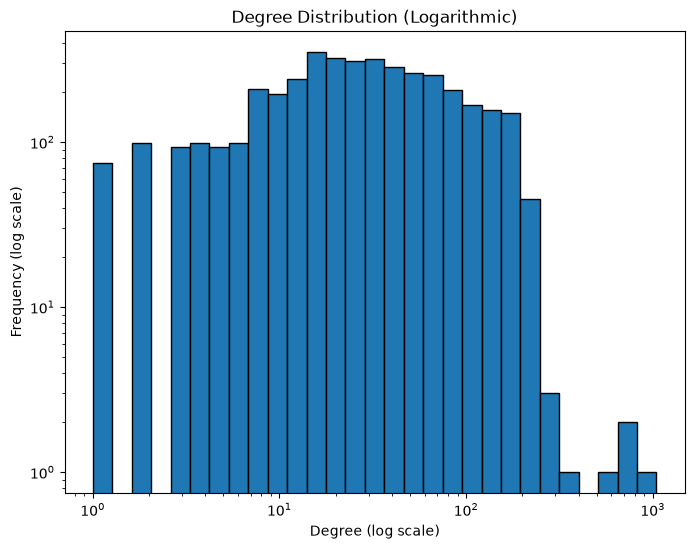

In [9]:
plt.figure(figsize=(8, 6))
plt.hist(degrees, bins=np.logspace(0, np.log10(degrees.max()), 30), edgecolor='black')
plt.xscale('log')
plt.yscale('log')
plt.xlabel('Degree (log scale)')
plt.ylabel('Frequency (log scale)')
plt.title('Degree Distribution (Logarithmic)')
plt.show()

## 3. Eigenvalues and eigenvectors of the adjacency matrix

We solve $A\mathbf{v} = \lambda \mathbf{v}$. Because $A$ is real and symmetric, all eigenvalues are real and the eigenvectors are orthogonal, so `np.linalg.eigh` is the right tool (it returns eigenvalues in ascending order).

In [10]:
eigvals, eigvecs = np.linalg.eigh(A)

lambda_1 = eigvals[-1]
print("Largest eigenvalue  (lambda_1) : %.4f" % lambda_1)
print("Smallest eigenvalue            : %.4f" % eigvals[0])
print("Sum of eigenvalues (= trace A) : %.6f" % eigvals.sum())
print()
print("Known bounds: average degree <= lambda_1 <= maximum degree")
print("  %.4f <= %.4f <= %.4f" % (degrees.mean(), lambda_1, degrees.max()))

Largest eigenvalue  (lambda_1) : 162.3739
Smallest eigenvalue            : -23.7546
Sum of eigenvalues (= trace A) : 0.000000

Known bounds: average degree <= lambda_1 <= maximum degree
  43.6910 <= 162.3739 <= 1045.0000


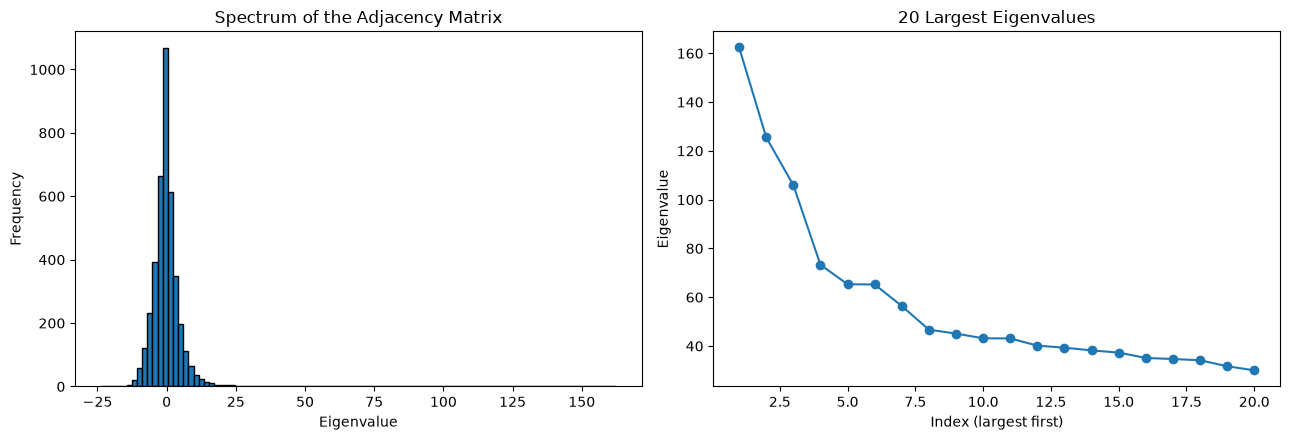

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

axes[0].hist(eigvals, bins=100, edgecolor='black')
axes[0].set_xlabel('Eigenvalue')
axes[0].set_ylabel('Frequency')
axes[0].set_title('Spectrum of the Adjacency Matrix')

top = eigvals[::-1][:20]
axes[1].plot(range(1, len(top) + 1), top, marker='o')
axes[1].set_xlabel('Index (largest first)')
axes[1].set_ylabel('Eigenvalue')
axes[1].set_title('20 Largest Eigenvalues')

plt.tight_layout()
plt.show()

## 4. Eigenvector centrality - identifying important nodes

A node is important if it is connected to other important nodes: $x_i = \frac{1}{\lambda}\sum_j A_{ij}x_j$, i.e. $A\mathbf{x} = \lambda\mathbf{x}$.
By the **Perron-Frobenius theorem**, a connected network's largest eigenvalue has an eigenvector with all entries of one sign, so we take that eigenvector (scaled to unit length) as the centrality score.

In [12]:
v1 = eigvecs[:, -1].copy()
if v1.sum() < 0:                              # eigenvectors are only defined up to sign
    v1 = -v1
eigen_centrality = v1

print("Smallest entry of v1 (should be >= 0) : %.2e" % eigen_centrality.min())
print("Check  ||A v - lambda v||             : %.2e" % np.linalg.norm(A @ v1 - lambda_1 * v1))

Smallest entry of v1 (should be >= 0) : 3.63e-14
Check  ||A v - lambda v||             : 1.27e-13


**Cross-check with power iteration.** Repeatedly multiplying a vector by $A$ converges to the leading eigenvector. We iterate with $A + I$ (same eigenvectors, and it avoids oscillation in bipartite-like networks).

In [13]:
def power_iteration(M, shift=1.0, tol=1e-10, max_iter=20000):
    x = np.ones(M.shape[0]) / np.sqrt(M.shape[0])
    for it in range(1, max_iter + 1):
        y = M @ x + shift * x
        y = y / np.linalg.norm(y)
        if np.linalg.norm(y - x) < tol:
            return y, it, True
        x = y
    return x, max_iter, False

pi_vector, iterations, converged = power_iteration(A)
pi_lambda = pi_vector @ A @ pi_vector

print("Converged:", converged, "after", iterations, "iterations")
print("Eigenvalue estimate from power iteration : %.6f" % pi_lambda)
print("Eigenvalue from eigh                     : %.6f" % lambda_1)
print("Cosine similarity of the two eigenvectors: %.8f" % abs(pi_vector @ eigen_centrality))

Converged: True after 86 iterations
Eigenvalue estimate from power iteration : 162.373942
Eigenvalue from eigh                     : 162.373942
Cosine similarity of the two eigenvectors: 1.00000000


In [14]:
top_idx = np.argsort(-eigen_centrality)[:10]

print("Top 10 nodes by eigenvector centrality")
print("%-5s %-8s %-12s %-8s" % ("Rank", "Node", "Centrality", "Degree"))
for rank, i in enumerate(top_idx, start=1):
    print("%-5d %-8d %-12.5f %-8d" % (rank, nodes[i], eigen_centrality[i], degrees[i]))

print()
print("Correlation between degree and eigenvector centrality: %.3f"
      % np.corrcoef(degrees, eigen_centrality)[0, 1])

Top 10 nodes by eigenvector centrality
Rank  Node     Centrality   Degree  
1     1912     0.09541      755     
2     2266     0.08698      234     
3     2206     0.08605      210     
4     2233     0.08517      222     
5     2464     0.08428      202     
6     2142     0.08419      221     
7     2218     0.08416      205     
8     2078     0.08414      204     
9     2123     0.08367      203     
10    1993     0.08353      203     

Correlation between degree and eigenvector centrality: 0.573


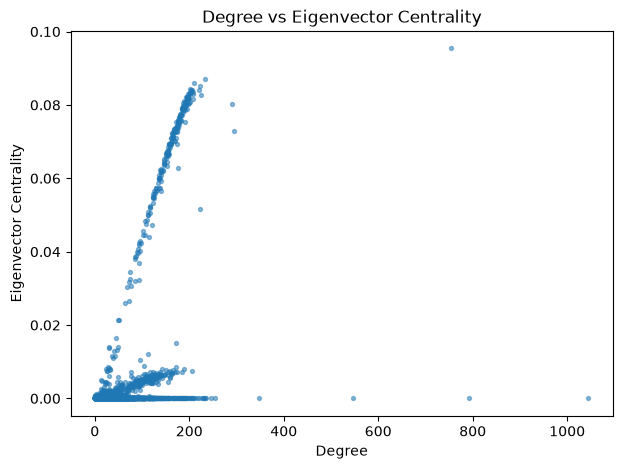

In [15]:
fig, ax = plt.subplots(figsize=(7, 5))
ax.scatter(degrees, eigen_centrality, s=8, alpha=0.5)
ax.set_xlabel('Degree')
ax.set_ylabel('Eigenvector Centrality')
ax.set_title('Degree vs Eigenvector Centrality')
plt.show()

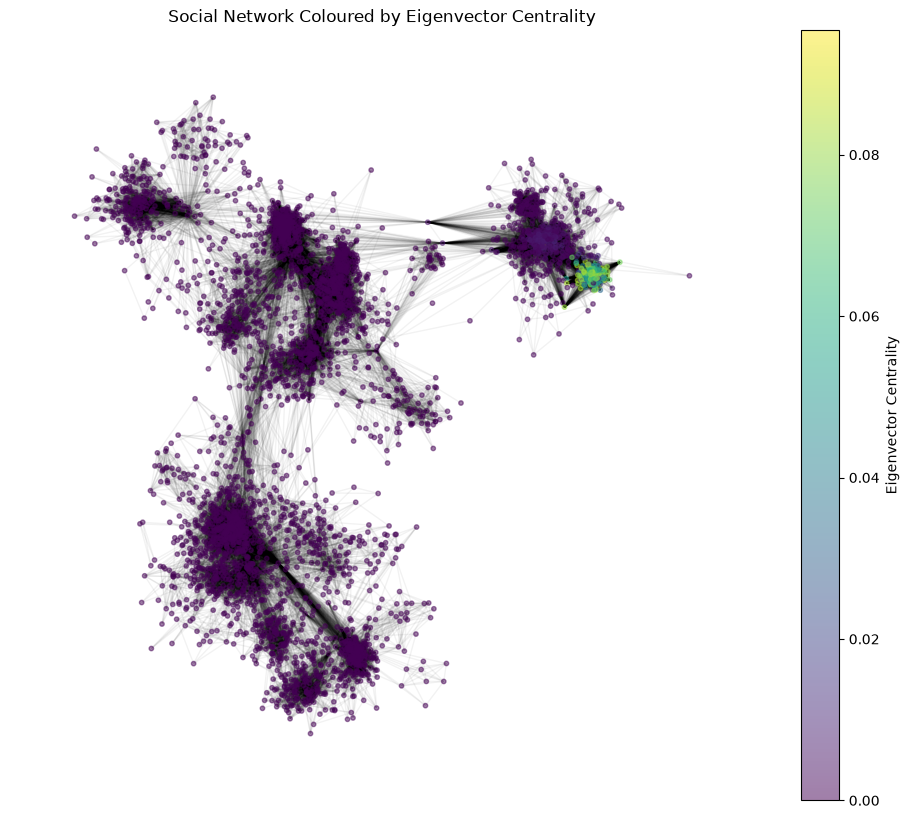

In [16]:
fig, ax = plt.subplots(figsize=(12, 10))
nodes_plot = nx.draw_networkx_nodes(social_network, pos, nodelist=nodes, node_size=10,
                                    node_color=eigen_centrality, cmap=plt.cm.viridis,
                                    alpha=0.5, ax=ax)
nx.draw_networkx_edges(social_network, pos, alpha=0.05, ax=ax)
fig.colorbar(nodes_plot, ax=ax, label='Eigenvector Centrality')
ax.set_title("Social Network Coloured by Eigenvector Centrality")
ax.axis('off')
plt.show()

## 5. The Laplacian matrix and spectral bisection

With the degree matrix $D = \mathrm{diag}(\mathbf{d})$, the **graph Laplacian** is $L = D - A$. Its spectral properties:

* all eigenvalues are $\ge 0$, and the smallest is $0$;
* the number of zero eigenvalues equals the number of connected components;
* the second-smallest eigenvalue $\lambda_2$ (**algebraic connectivity**) measures how well connected the network is, and its eigenvector - the **Fiedler vector** - splits the network into two groups by sign.

For a split $s_i = \pm 1$, the number of edges between the two groups is $\tfrac14\, s^{T} L\, s$.

In [17]:
D = np.diag(degrees)
L = D - A

lap_vals, lap_vecs = np.linalg.eigh(L)

print("Smallest Laplacian eigenvalue          : %.2e (should be ~0)" % lap_vals[0])
print("Zero eigenvalues (connected components): %d" % np.sum(lap_vals < 1e-8))
print("Algebraic connectivity (lambda_2)      : %.5f" % lap_vals[1])

Smallest Laplacian eigenvalue          : 1.09e-14 (should be ~0)
Zero eigenvalues (connected components): 1
Algebraic connectivity (lambda_2)      : 0.01815


Group sizes (negative / positive entries): [3285  754]
Edges between the two groups (1/4 s^T L s): 40


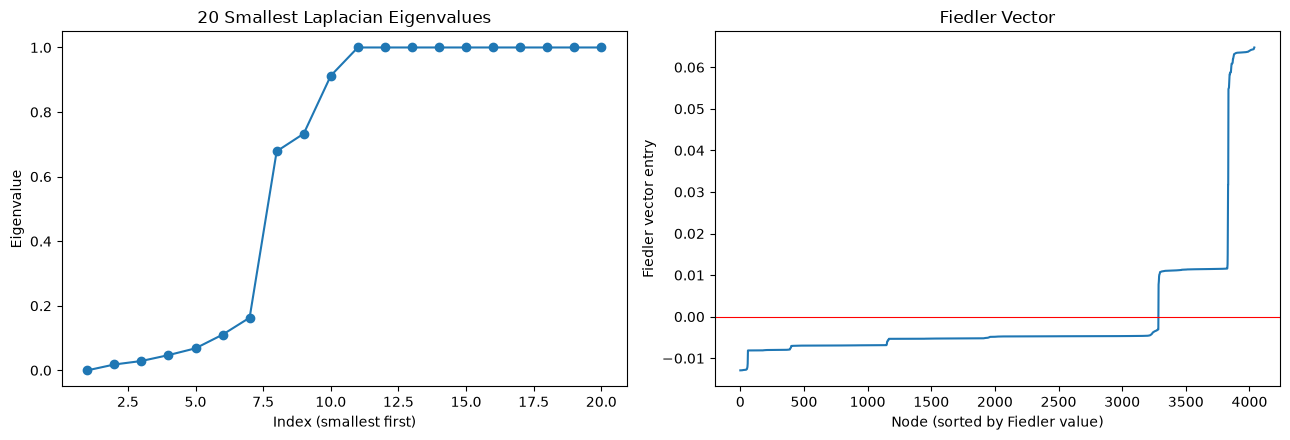

In [18]:
fiedler = lap_vecs[:, 1]
fiedler_groups = (fiedler >= 0).astype(int)       # sign of the Fiedler vector

s = np.where(fiedler_groups == 1, 1.0, -1.0)
cut_edges = int(round(0.25 * s @ L @ s))

print("Group sizes (negative / positive entries):", np.bincount(fiedler_groups))
print("Edges between the two groups (1/4 s^T L s):", cut_edges)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

axes[0].plot(range(1, 21), lap_vals[:20], marker='o')
axes[0].set_xlabel('Index (smallest first)')
axes[0].set_ylabel('Eigenvalue')
axes[0].set_title('20 Smallest Laplacian Eigenvalues')

axes[1].plot(np.sort(fiedler))
axes[1].axhline(0, color='red', linewidth=0.8)
axes[1].set_xlabel('Node (sorted by Fiedler value)')
axes[1].set_ylabel('Fiedler vector entry')
axes[1].set_title('Fiedler Vector')

plt.tight_layout()
plt.show()

## 6. Community detection with the modularity matrix

Communities are groups with more internal edges than expected by chance. With degrees $k_i$ and $2m$ = total degree, the **modularity matrix** is

$$B_{ij} = A_{ij} - \frac{k_i k_j}{2m},$$

and the modularity of a partition is $Q = \frac{1}{2m}\,\mathrm{trace}(S^{T} B S)$, where $S$ is the node-by-community membership matrix. Large positive eigenvalues of $B$ point to community structure, and the corresponding eigenvectors tell us which nodes belong together.

In [19]:
B = A - np.outer(degrees, degrees) / (2 * m)

def modularity(labels):
    labels = np.unique(labels, return_inverse=True)[1]   # relabel to 0..c-1
    S = np.eye(labels.max() + 1)[labels]                 # membership matrix
    return np.sum(S * (B @ S)) / (2 * m)

mod_vals, mod_vecs = np.linalg.eigh(B)
n_positive = int(np.sum(mod_vals > 1e-8))

print("Largest eigenvalues of B:", np.round(mod_vals[::-1][:8], 3))
print("Positive eigenvalues of B:", n_positive)
print()
print("Modularity of the Fiedler (Laplacian) split : %.4f" % modularity(fiedler_groups))

leading_split = (mod_vecs[:, -1] >= 0).astype(int)       # sign of leading eigenvector of B
print("Modularity of the leading-eigenvector split: %.4f" % modularity(leading_split))

Largest eigenvalues of B: [149.226 113.368  92.113  69.322  65.234  57.894  49.808  45.652]
Positive eigenvalues of B: 1672

Modularity of the Fiedler (Laplacian) split : 0.1526
Modularity of the leading-eigenvector split: 0.3066


**More than two communities.** Each node gets coordinates from the top eigenvectors of $B$ (scaled by $\sqrt{\lambda}$ and then normalised to unit length, so that high-degree hubs do not dominate), and nearby nodes are grouped with k-means. We try several numbers of communities $k$ and keep the one with the highest modularity $Q$.

In [20]:
def kmeans(X, k, n_init=10, max_iter=300, seed=0):
    rng = np.random.default_rng(seed)
    n_points = X.shape[0]
    best_labels, best_inertia = None, np.inf
    for _ in range(n_init):
        centers = [X[rng.integers(n_points)]]            # k-means++ initialisation
        for _ in range(1, k):
            d2 = ((X[:, None, :] - np.array(centers)[None, :, :]) ** 2).sum(axis=2).min(axis=1)
            if d2.sum() == 0:
                centers.append(X[rng.integers(n_points)])
            else:
                centers.append(X[rng.choice(n_points, p=d2 / d2.sum())])
        centers = np.array(centers)
        for _ in range(max_iter):
            dist = ((X[:, None, :] - centers[None, :, :]) ** 2).sum(axis=2)
            labels = dist.argmin(axis=1)
            new_centers = np.array([X[labels == j].mean(axis=0) if np.any(labels == j) else centers[j]
                                    for j in range(k)])
            shift = np.abs(new_centers - centers).max()
            centers = new_centers
            if shift < 1e-9:
                break
        dist = ((X[:, None, :] - centers[None, :, :]) ** 2).sum(axis=2)
        labels = dist.argmin(axis=1)
        inertia = dist[np.arange(n_points), labels].sum()
        if inertia < best_inertia:
            best_inertia, best_labels = inertia, labels
    return best_labels

k_max = max(2, min(15, n_positive + 1))
results = {}
for k in range(2, k_max + 1):
    dims = max(1, min(k - 1, n_positive))
    coords = mod_vecs[:, -dims:] * np.sqrt(np.clip(mod_vals[-dims:], 0, None))
    norms = np.linalg.norm(coords, axis=1, keepdims=True)
    coords = coords / np.where(norms == 0, 1, norms)       # unit length: hubs must not dominate the clustering
    labels_k = kmeans(coords, k)
    results[k] = (labels_k, modularity(labels_k))

print("Communities (k) vs modularity (Q)")
for k, (_, q) in results.items():
    print("  k = %d   Q = %.4f" % (k, q))

best_k = max(results, key=lambda k: results[k][1])
labels = np.unique(results[best_k][0], return_inverse=True)[1]
n_communities = labels.max() + 1
best_Q = modularity(labels)
print()
print("Best choice: %d communities, modularity Q = %.4f" % (n_communities, best_Q))

Communities (k) vs modularity (Q)
  k = 2   Q = 0.3066
  k = 3   Q = 0.5312
  k = 4   Q = 0.6459
  k = 5   Q = 0.7072
  k = 6   Q = 0.7873
  k = 7   Q = 0.7913
  k = 8   Q = 0.8122
  k = 9   Q = 0.8062
  k = 10   Q = 0.7653
  k = 11   Q = 0.8182
  k = 12   Q = 0.7782
  k = 13   Q = 0.7842
  k = 14   Q = 0.7735
  k = 15   Q = 0.7697

Best choice: 11 communities, modularity Q = 0.8182


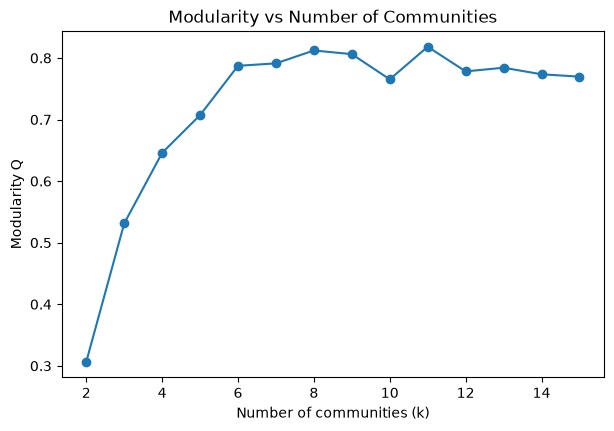

In [21]:
ks = list(results.keys())
plt.figure(figsize=(7, 4.5))
plt.plot(ks, [results[k][1] for k in ks], marker='o')
plt.xlabel('Number of communities (k)')
plt.ylabel('Modularity Q')
plt.title('Modularity vs Number of Communities')
plt.show()

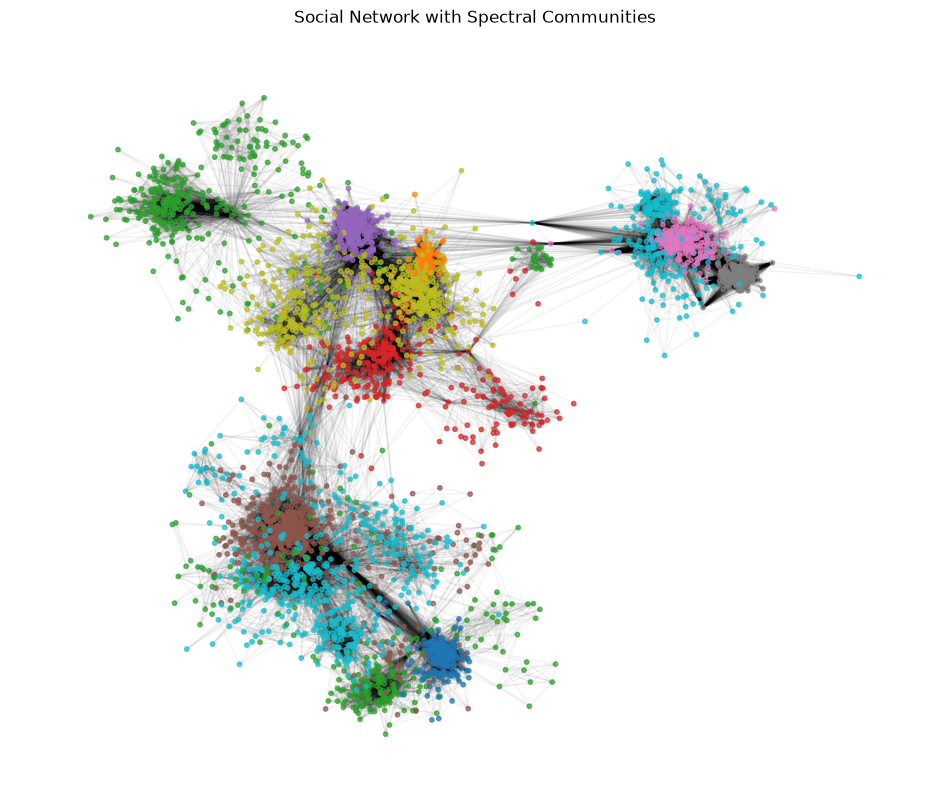

In [22]:
fig, ax = plt.subplots(figsize=(12, 10))
nx.draw_networkx_nodes(social_network, pos, nodelist=nodes, node_size=10,
                       node_color=labels, cmap=plt.cm.tab10, vmin=0, vmax=9,
                       alpha=0.7, ax=ax)
nx.draw_networkx_edges(social_network, pos, alpha=0.05, ax=ax)
ax.set_title("Social Network with Spectral Communities")
ax.axis('off')
plt.show()

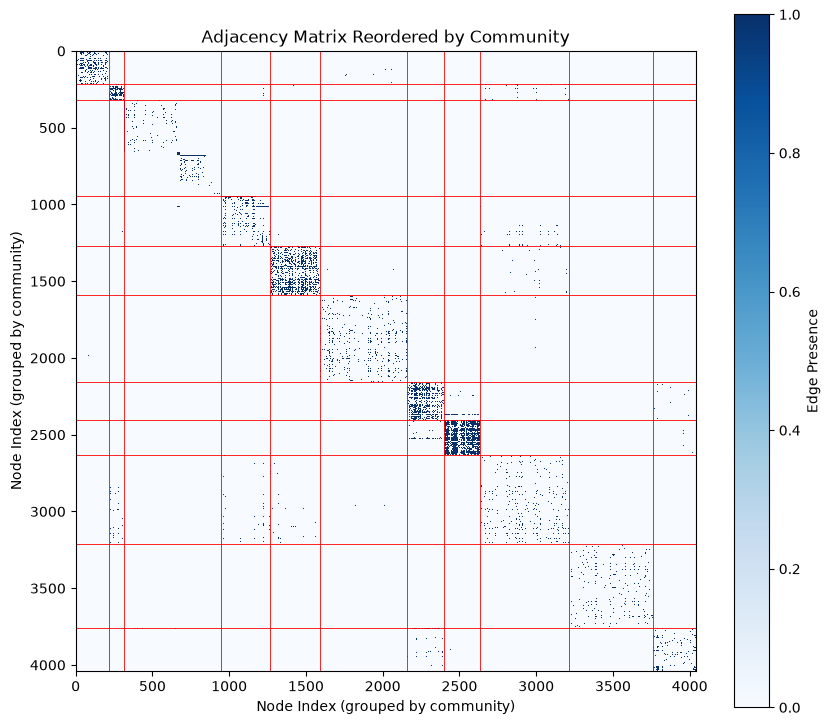

In [23]:
order = np.argsort(labels, kind='stable')
A_sorted = A[np.ix_(order, order)]
boundaries = np.cumsum(np.bincount(labels))[:-1]

plt.figure(figsize=(10, 9))
plt.imshow(A_sorted, cmap='Blues', interpolation='nearest')
for b in boundaries:
    plt.axvline(b - 0.5, color='red', linewidth=0.6)
    plt.axhline(b - 0.5, color='red', linewidth=0.6)
plt.colorbar(label='Edge Presence')
plt.title('Adjacency Matrix Reordered by Community')
plt.xlabel('Node Index (grouped by community)')
plt.ylabel('Node Index (grouped by community)')
plt.show()

## 7. Important nodes inside each community

Combining the two parts: for every community, its size and its most central node (by eigenvector centrality).

In [24]:
print("%-10s %-6s %-10s %-12s %-12s" % ("Community", "Size", "Top node", "Centrality", "Mean centr."))
for c in range(n_communities):
    members = np.where(labels == c)[0]
    best = members[np.argmax(eigen_centrality[members])]
    print("%-10d %-6d %-10d %-12.5f %-12.6f"
          % (c, len(members), nodes[best], eigen_centrality[best], eigen_centrality[members].mean()))

Community  Size   Top node   Centrality   Mean centr. 
0          215    2839       0.00000      0.000000    
1          103    896        0.00000      0.000002    
2          627    0          0.00003      0.000001    
3          324    563        0.00060      0.000007    
4          322    1361       0.00013      0.000017    
5          565    1534       0.00005      0.000000    
6          247    2543       0.07287      0.004500    
7          229    2266       0.08698      0.061786    
8          582    58         0.00059      0.000004    
9          548    1085       0.00000      0.000000    
10         277    1912       0.09541      0.001171    


In [25]:
print("SUMMARY")
print("-------")
print("Network                         : %d nodes, %d edges" % (n, m))
print("Largest adjacency eigenvalue    : %.4f" % lambda_1)
print("Most central node               : %d (centrality %.5f)" % (nodes[top_idx[0]], eigen_centrality[top_idx[0]]))
print("Algebraic connectivity          : %.5f" % lap_vals[1])
print("Communities found (spectral)    : %d" % n_communities)
print("Modularity of the partition     : %.4f" % best_Q)

SUMMARY
-------
Network                         : 4039 nodes, 88234 edges
Largest adjacency eigenvalue    : 162.3739
Most central node               : 1912 (centrality 0.09541)
Algebraic connectivity          : 0.01815
Communities found (spectral)    : 11
Modularity of the partition     : 0.8182
